# cpbench: synthetic benchmark for latent change-point detection and regime clustering

This notebook is the display layer of the `cpbench` package. The pipeline has three separate layers:
- **Datasets** (`cpbench.data`): a regime process, signal and nuisance sources, and a corruption chain.
- **Feature learners** (`cpbench.features`): windows → feature vectors. These are raw statistics, oracles, or self-supervised encoders (JEPA, AE, VAE, CPC, TS2Vec). They make no decisions.
- **Detectors** (`cpbench.detectors`): change-point detection and regime clustering *on top of* any learner's features. These are GMM, HMM, AR-HMM, temporal excess, contrast, MMD and BOCPD.

Heavy work runs outside the notebook:
- **In Python:** `Benchmark(dataset, detectors=[...]).run(make_learner("jepa_shared", window=32, gap=32))` fits the learner (resumable), caches its features and runs every detector on them.
- **From the shell or on HPC:** `python -m cpbench.run dataset=<yaml> features=... seed=... hp.window=... detectors=[...]`. SLURM arrays come from `cpbench/hpc/make_sweep.py`.
- **Audit:** `python -m cpbench.eval.audit --grid cpbench/configs/grid_synthetic.yaml` measures how hard each dataset is for cheap features.

**Datasets are identified by their construction.** Each one is a pipeline: regime process → signal source(s) → nuisance sources → corruption chain, plus a seed. Its id reads `regime|signal|nuisance|corruption#hash`, and the results tables have one column per slot. A grid of datasets is a YAML file listing the alternatives in each slot. The standard grid is `cpbench/configs/grid_synthetic.yaml`: 11 change types × 2 nuisance sets × 5 corruption chains.

**Sources are switching linear signals**: any parameter may depend on the regime, and nonlinearities are transforms. The standard change types in the grid are recipes, ordered by the cheapest statistic that can see the regime:

| What a single window reveals | Change types (recipes in the grid file) |
|---|---|
| the mean or a trend | mean (level + AR), trend |
| per-channel second-order statistics | variance, mean+variance, autocorrelation (`ar` phi), spectral (`oscillator` freq) |
| cross-channel second-order statistics | correlation (per-regime `linear` mixing), lead-lag (per-regime `delay`) |
| only higher-order structure | skew (mirrored `pointwise`), phase coupling |
| nothing: the regime acts only on transitions | transition |

**The data are continuous series, and regimes switch at arbitrary samples.** The model window W and the context/target gap are *model hyperparameters* in samples, swept like any other and never set from knowledge of the regimes. All scoring is at sample level.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, json
from cpbench.data import Dataset, expand, available, register_source, register_transform
from cpbench.data.sources import Channels
from cpbench.data.transforms import Transform
from cpbench import Benchmark, make_learner, make_detector
from cpbench.tests.test_invariants import RECIPES, signals, regime_stats
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 9})
REG_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#9b59b6", "#c0392b", "#7f8c8d"]
RESULTS = "cpbench_results"; RUNS = "cpbench_runs"
GRID = "cpbench/configs/grid_synthetic.yaml"
SIGNALS = signals()                     # change type -> clean dataset config (the grid's signal recipes, uncorrupted)

## 1. Change types

Each change-type recipe of the grid on its own, uncorrupted: two channels over 960 samples. The background colour is the regime and the dashed lines are change points. Switches fall anywhere, not on a window grid.

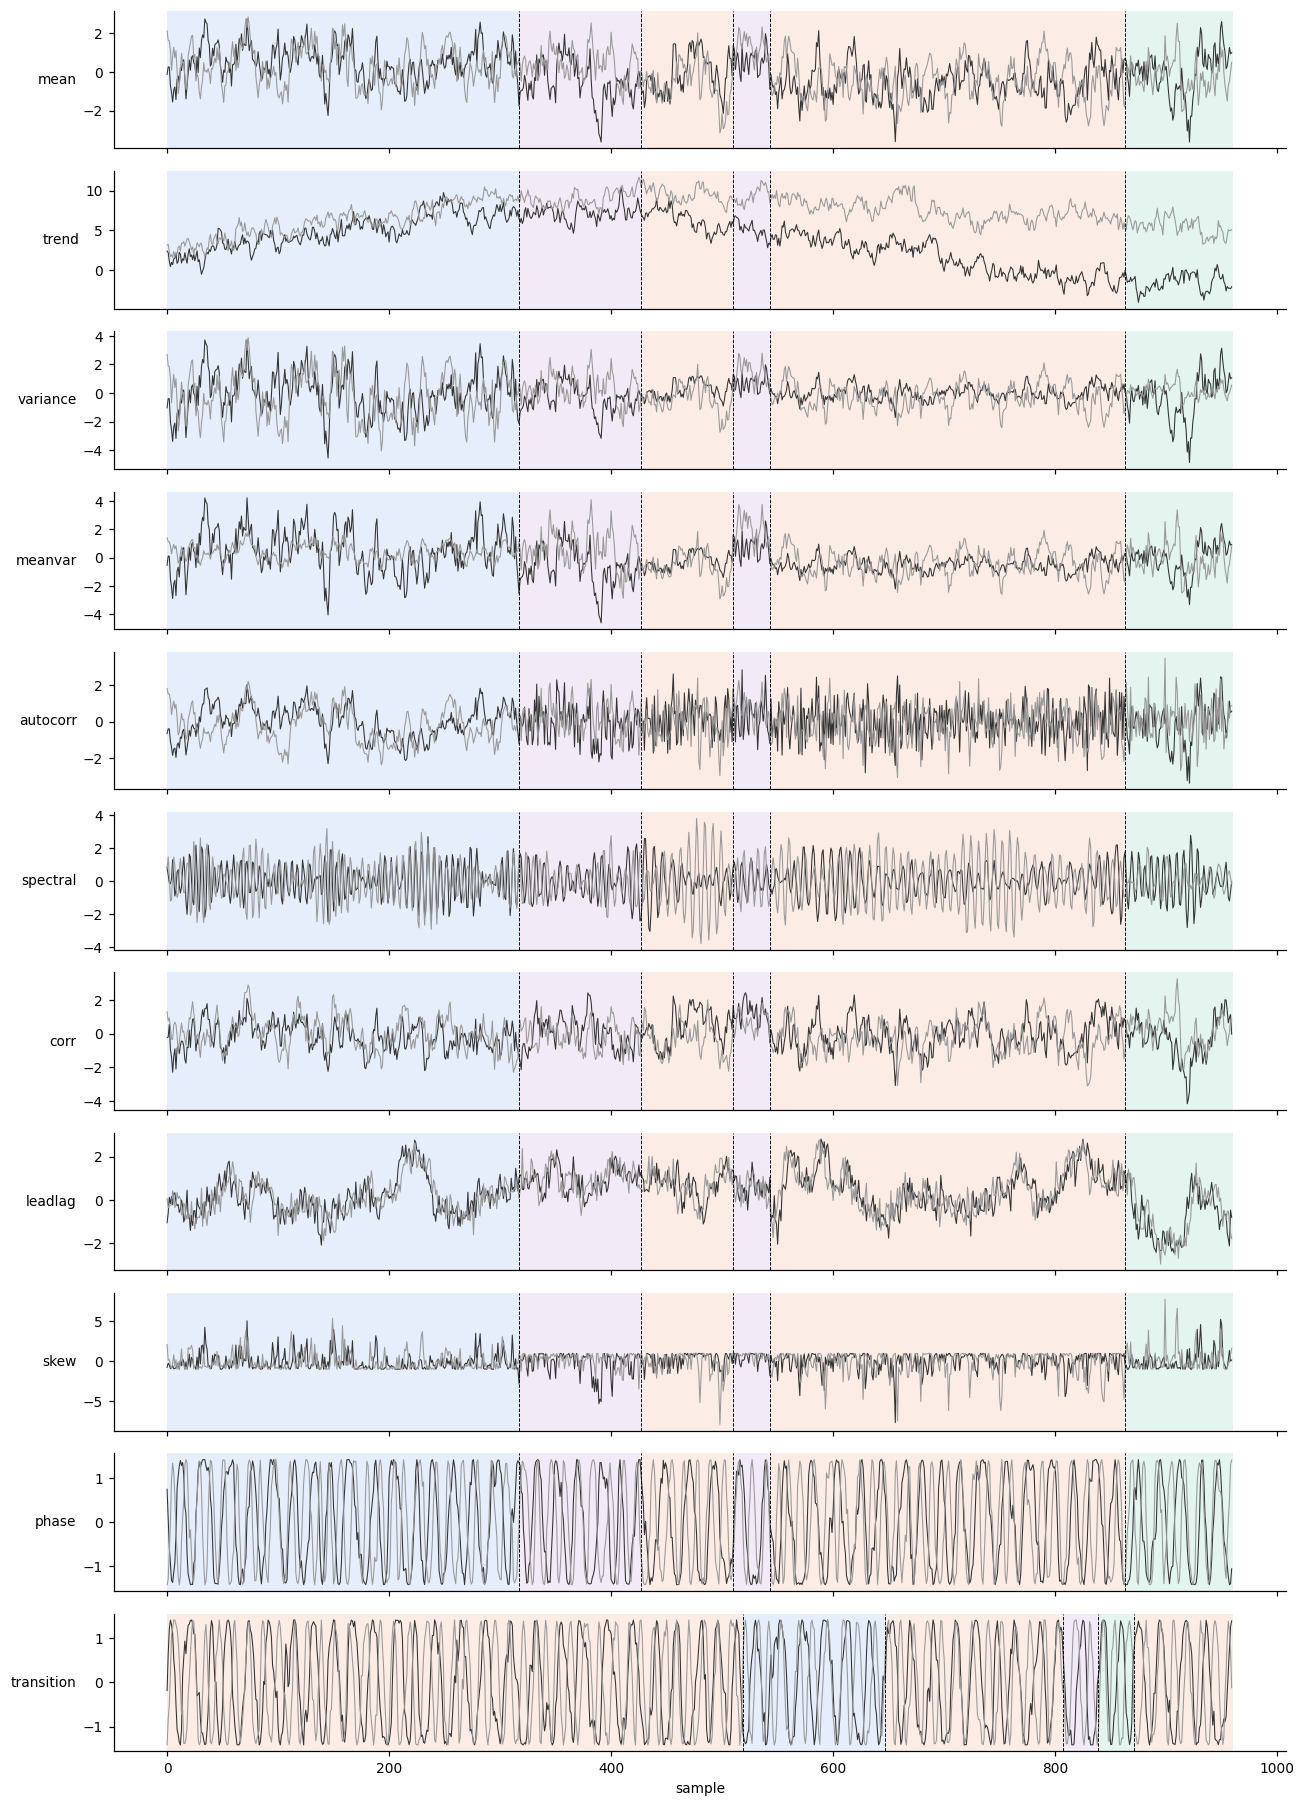

In [2]:
def shade(ax, S_s):
    b = np.r_[0, np.flatnonzero(np.diff(S_s)) + 1, len(S_s)]
    for a, c in zip(b[:-1], b[1:]):
        ax.axvspan(a, c, color=REG_COLORS[S_s[a]], alpha=0.12, lw=0)

fig, axs = plt.subplots(len(SIGNALS), 1, figsize=(12, 1.5 * len(SIGNALS)), sharex=True)
for ax, (name, cfg) in zip(axs, SIGNALS.items()):
    ds = Dataset(cfg); d = ds.sample(1, 960, np.random.default_rng(3))
    x = d["obs"][0]; S_s = d["S_s"][0]
    shade(ax, S_s)
    ax.plot(x[:, 0], lw=0.7, color="#333"); ax.plot(x[:, 1] if x.shape[1] > 1 else x[:, 0], lw=0.7, color="#999")
    for t in np.flatnonzero(d["cp_s"][0]): ax.axvline(t, color="k", ls="--", lw=0.6)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
axs[-1].set_xlabel("sample"); plt.tight_layout(); plt.show()

## 2. Corruption chains\n\nThe standard grid's nuisance sets and corruption chains, applied to one change type (spectral). Each panel shows the first 16 observed channels over 400 samples, with the regime as a colour bar above and the dataset id in the title.

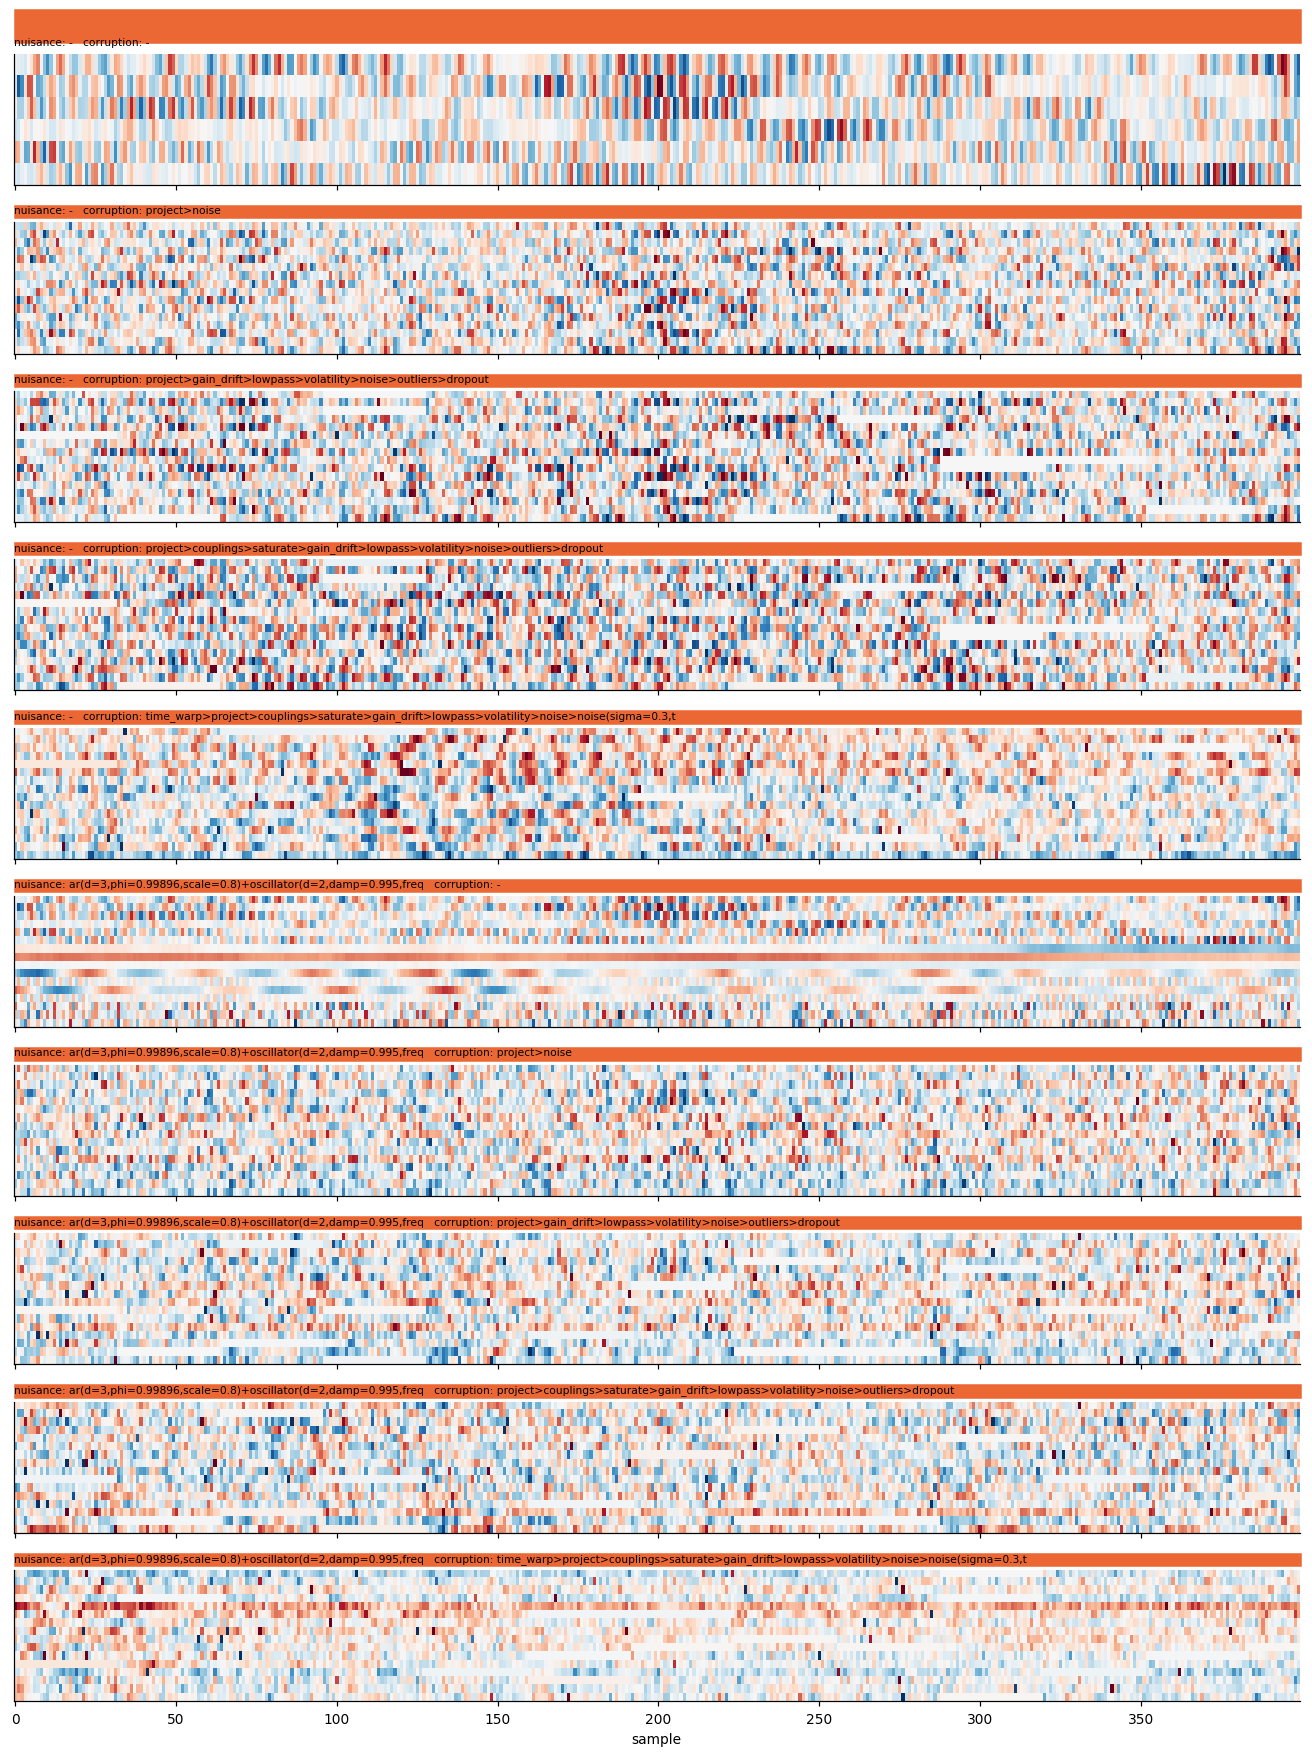

In [3]:
grid = [c for c in expand(GRID) if c["sources"][0]["type"] == "oscillator"]
fig, axs = plt.subplots(len(grid), 1, figsize=(12, 1.6 * len(grid)), sharex=True)
for ax, cfg in zip(axs, grid):
    ds = Dataset(cfg); d = ds.sample(1, 400, np.random.default_rng(4))
    ax.imshow(d["obs"][0][:, :16].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest")
    S_s = d["S_s"][0]; b = np.r_[0, np.flatnonzero(np.diff(S_s)) + 1, len(S_s)]
    for a, c in zip(b[:-1], b[1:]): ax.add_patch(plt.Rectangle((a, -2.5), c - a, 1.5, color=REG_COLORS[S_s[a]], clip_on=False))
    i = ds.info; ax.set_title(f"nuisance: {i.nuisance[:60]}   corruption: {i.corruption[:90]}", fontsize=7, loc="left"); ax.set_yticks([])
axs[-1].set_xlabel("sample"); plt.tight_layout(); plt.show()

## 3. Composing datasets

A dataset is a pipeline: **regime process(es) → sources → transforms**, plus a seed. It's written as a plain dict or a YAML file; the dict is also the cache key and the run identity. Grids of datasets are YAML files of component slots (`cpbench.data.expand`).

- **Regimes:** `markov` (dwell distribution, cyclic option), `scripted`, `single_cp`, `none`. Several named regimes give factorial structure; `target` names the one that is scored.
- **Sources:** switching linear signals (`level`, `white`, `ar`, `oscillator`, `trend`, `impulses`) whose parameters may depend on the regime, the structured `phase` and `transition`, and `composite` (sources plus their own transforms).
- **Transforms:** `linear` (optionally per-regime matrices), `delay` (per-regime lags), `pointwise` (optionally mirrored per regime), `bandpass`, `project`, `couplings`, `saturate`, `gain_drift`, `lowpass`, `volatility`, `noise` (white or coloured), `wander`, `outliers`, `dropout` (writes a missing-data mask) and `time_warp` (moves the labels too). Per-channel standardisation is always applied at the end, unless the config sets `standardize: false`.

All timescales are in samples.

In [4]:
print("regimes:", available("regime")); print("sources:", available("source")); print("transforms:", available("transform"))

regimes: ['markov', 'none', 'scripted', 'single_cp']
sources: ['ar', 'composite', 'impulses', 'level', 'oscillator', 'phase', 'transition', 'trend', 'white']
transforms: ['bandpass', 'couplings', 'delay', 'dropout', 'gain_drift', 'linear', 'lowpass', 'noise', 'outliers', 'pointwise', 'project', 'saturate', 'time_warp', 'volatility', 'wander']


Dataset(main=markov(K=3,dwell=300),aux=markov(K=2,dwell=1500)|oscillator(d=2,freq={base:0.08,spread:0.03})+ar(d=2,regime=aux,sigma=[0.5,2.0])|ar(d=3,phi=0.999,scale=2)|project(D=32)>couplings(n=2)>noise(sigma=0.4)>dropout#25573b11, D=32)


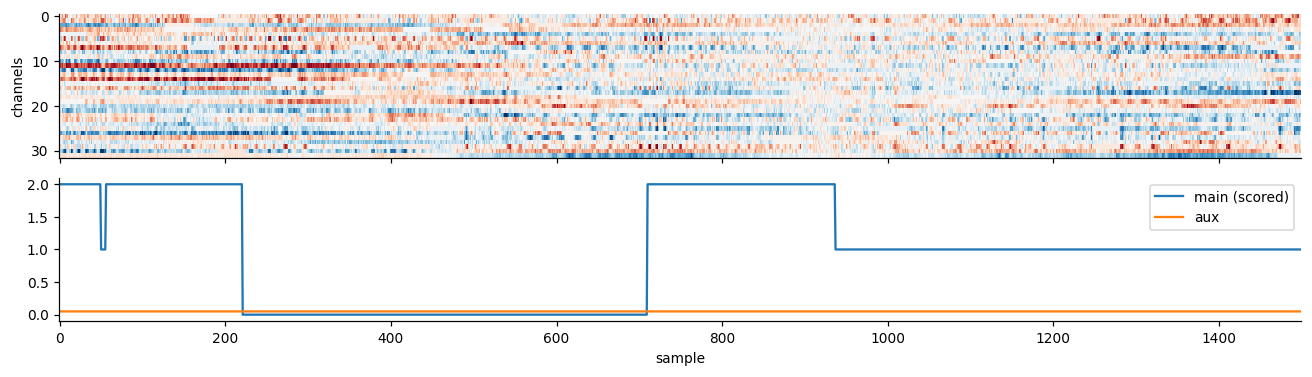

In [5]:
# a custom composition: two change types driven by two independent regime processes (factorial),
# a nuisance, and a short corruption chain; only the "main" regime is scored
spec = dict(
    regimes={"main": dict(type="markov", K=3, dwell=300), "aux": dict(type="markov", K=2, dwell=1500)},
    target="main",
    sources=[dict(type="oscillator", d=2, freq={"base": 0.08, "spread": 0.03}), dict(type="ar", d=2, sigma=[0.5, 2.0], regime="aux"),
             dict(type="ar", d=3, phi=0.999, scale=2.0)],
    transforms=[dict(type="project", D=32), dict(type="couplings", n=2), dict(type="noise", sigma=0.4),
                dict(type="dropout", rate=0.05)],
    splits={"test": [8, 32000], "val": [2, 9600]})
ds = Dataset(spec); print(ds)
d = ds.sample(1, 1500, np.random.default_rng(0))
fig, axs = plt.subplots(2, 1, figsize=(12, 3.5), sharex=True)
axs[0].imshow(d["obs"][0].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3, interpolation="nearest"); axs[0].set_ylabel("channels")
axs[1].plot(d["S_s"][0], label="main (scored)"); axs[1].plot(d["S_aux"][0] + 0.05, label="aux"); axs[1].legend(); axs[1].set_xlabel("sample")
plt.tight_layout(); plt.show()

In [6]:
# new components plug in through the registries and are usable in any spec (and therefore in Benchmark / sweeps)
@register_source("square_wave")
class SquareWave(Channels):
    """Regime k sets the period of a square wave (a custom source; the same is possible with oscillator + pointwise)."""
    defaults = dict(periods=[8, 16, 32, 64])
    def extra_driven(self):
        return True
    def simulate(self, ctx):
        periods = np.array(self.periods)[: self.K]
        t = np.arange(ctx.S.shape[1])[None]
        return np.sign(np.sin(2 * np.pi * t / periods[ctx.S]))[..., None].repeat(self.d, -1)

@register_transform("quantize")
class Quantize(Transform):
    """Sensor quantisation to a fixed step."""
    defaults = dict(step=0.5)                     # every parameter is declared; unknown keys are rejected
    def apply(self, b, rng):
        b.x = np.round(b.x / self.step) * self.step

ds2 = Dataset(dict(regime=dict(type="markov", K=4, dwell=400), sources=[dict(type="square_wave"), dict(type="white", d=2)],
                   transforms=[dict(type="project", D=8), dict(type="noise", sigma=0.3), dict(type="quantize", step=0.5)],
                   splits={"test": [4, 16000], "val": [2, 9600]}))
print(ds2)
bench2 = Benchmark(ds2, detectors=["hmm"], probes=False, out="cpbench_runs_local", log=lambda *a: None)
bench2.compare([make_learner("raw_spectra", window=32), make_learner("raw_stats", window=32)], detector="hmm", metric="acc")

Dataset(markov(dwell=400)|square_wave|white(d=2)|project(D=8)>noise(sigma=0.3)>quantize#631fe5c7, D=8)


,,,,acc
features,W,gap,seed,
raw_spectra,32,0,0,0.473
raw_stats,32,0,0,0.362


## 4. Matched statistics

For every change type, the table gives the largest difference across regimes of four per-sample statistics of the clean signal. An asterisk marks a statistic the recipe keeps equal across regimes; `pytest cpbench/tests` enforces those.

The cross-channel and higher-order changes should show near-zero spread in all four columns, because their regime lives elsewhere: in lags, higher orders or transitions.

In [7]:
rows = []
for (name, matched, changed), cfg in zip(RECIPES, SIGNALS.values()):
    ds = Dataset(cfg); d = ds.sample(16, 9600, np.random.default_rng(5))
    st = regime_stats(d["obs"].astype(float), d["S_s"], ds.K)
    rows.append({"change type": name, **{k + ("*" if k in matched else ""): float(np.abs(st[k] - st[k].mean(0)).max())
                                        for k in ("mean", "var", "acf1", "corr0")}})
pd.DataFrame(rows).set_index("change type").round(3)

,mean,var*,acf1*,corr0*,var,acf1,corr0,mean*
change type,,,,,,,,
mean,0.513,0.041,0.008,0.023,NaN,NaN,NaN,NaN
trend,4.000,NaN,NaN,NaN,34.440,0.000,0.126,NaN
variance,NaN,NaN,0.008,0.022,1.357,NaN,NaN,0.027
meanvar,0.511,NaN,0.007,0.024,1.366,NaN,NaN,NaN
autocorr,NaN,0.023,NaN,0.022,NaN,0.511,NaN,0.015
spectral,NaN,0.070,NaN,0.048,NaN,0.152,NaN,0.003
corr,NaN,0.019,0.004,NaN,NaN,NaN,0.775,0.024
leadlag,NaN,0.042,0.007,0.036,NaN,NaN,NaN,0.054
skew,NaN,0.053,0.013,0.009,NaN,NaN,NaN,0.017


## 5. Recoverability audit (cheap features)

The audit runs every fixed feature learner `raw_<feature>` on each dataset of the grid, with every standard detector on top. It also runs the oracles `oracle_clean` (the uncorrupted signal) and `oracle_hidden` (a source's hidden state).

The heatmaps show the **best** raw feature × detector per dataset. That's an optimistic upper bound for cheap methods: the maximisation uses labels, and that's deliberate. Rows are signal sources and columns are nuisance × corruption chain; the legend below maps column numbers to chains.

Produce the table with `python -m cpbench.eval.audit --grid cpbench/configs/grid_synthetic.yaml --jobs 2`.

In [8]:
path = os.path.join(RESULTS, "audit.csv")
if os.path.exists(path):
    au = pd.read_csv(path); au = au[(au.detector != "probe") & (au.view == "features")]
    au["column"] = au.nuisance.ne("-").map({False: "", True: "N+"}) + au.corruption
    cols = sorted(au.column.unique(), key=lambda c: (c.startswith("N+"), len(c)))
    raw = au[au.features.str.startswith("raw_")]
    fig, axs = plt.subplots(1, 2, figsize=(14, 0.45 * raw.signal.nunique() + 1.5))
    for ax, (metric, title, vmin) in zip(axs, [("acc", "best raw clustering accuracy (chance 0.25)", 0.25), ("cp_ap", "best raw change-point AP", 0.0)]):
        piv = raw[raw.metric == metric].groupby(["signal", "column"]).value.max().unstack().reindex(columns=cols)
        im = ax.imshow(piv.values, cmap="viridis", vmin=vmin, vmax=1, aspect="auto")
        ax.set_xticks(range(len(cols)), [str(j) for j in range(len(cols))]); ax.set_yticks(range(len(piv)), piv.index)
        for r in range(piv.shape[0]):
            for c in range(piv.shape[1]):
                v = piv.values[r, c]
                if np.isfinite(v): ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=6, color="w" if v < 0.7 else "k")
        ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.03)
    plt.tight_layout(); plt.show()
    for j, c in enumerate(cols): print(f"{j}: {c[:150]}")
else:
    print("no audit yet:", path)

no audit yet: cpbench_results/audit.csv


In [9]:
# best cheap method per dataset, and the oracles for comparison
if os.path.exists(path):
    acc = au[au.metric == "acc"]
    best = acc[acc.features.str.startswith("raw_")].sort_values("value").groupby("dataset").tail(1)
    orc = acc[acc.features.str.startswith("oracle")].groupby("dataset").value.max().rename("best oracle")
    display(best.set_index("dataset")[["signal", "column", "W", "features", "detector", "value"]].join(orc).sort_values(["signal", "column"]))

## 6. Feature learners and detectors

A **feature learner** has parameters, including the `window` and, for learnt ones, the `gap`, both in samples. It implements `fit(dataset)` (a no-op for fixed features) and `embed(windows) -> vectors`. A **detector** has its own parameters and implements `detect(Z, K) -> labels and/or change scores`.

The benchmark fits each learner once, caches its features of the test split, and runs every detector on top. Results are cached per detector, so adding a learner or a detector only computes what's new. A classical baseline is just a pair, for example `raw_stats × hmm` or `raw_spectra × bocpd`.

`quick=True` uses small test and validation sets for fast iteration.

In [10]:
from cpbench.features import LEARNERS
from cpbench.detectors import DETECTORS
print("trainable learners:", LEARNERS.available(lambda c: c.trainable))
print("fixed learners:", LEARNERS.available(lambda c: not c.trainable))
print("detectors:", DETECTORS.available())

trainable learners: ['ae', 'bvae4', 'cpc', 'jepa', 'jepa_mlp_separate', 'jepa_mlp_shared', 'jepa_separate', 'jepa_separate_full', 'jepa_shared', 'ts2vec', 'vae']
fixed learners: ['oracle', 'oracle_clean', 'oracle_hidden', 'raw', 'raw_bispec', 'raw_coskew', 'raw_cov', 'raw_flat', 'raw_lagcov', 'raw_mean', 'raw_spectra', 'raw_stats']
detectors: ['arhmm', 'bocpd', 'contrast', 'gmm', 'hmm', 'mmd', 'temporal_excess']


In [11]:
DATASET = dict(regime=dict(type="markov", K=4, dwell=320), sources=[dict(type="ar", d=4, phi={"base": 0.4, "spread": 0.5})],
               transforms=[dict(type="project", D=64), dict(type="noise", sigma=0.5)])
bench = Benchmark(DATASET, detectors=["hmm", "arhmm", "bocpd"], quick=True, out="cpbench_runs_local")
small = dict(steps=300, batch=128, workers=1, eval_every=100)        # a few hundred steps: interface demo, not a result
learners = [make_learner("raw_stats", window=16), make_learner("raw_spectra", window=32),
            make_learner("jepa_shared", window=32, gap=32, **small), make_learner("ae", window=32, **small)]
df = pd.concat([bench.run(f) for f in learners])
df[(df.view == "features") & df.metric.isin(["acc", "cp_ap"])].pivot_table(index=["features", "W"], columns=["detector", "metric"], values="value").round(3)

[raw_stats x hmm] 2s
[raw_stats x arhmm] 2s
[raw_stats x bocpd] 0s
[raw_stats x probe] 0s
[raw_spectra x hmm] 1s
[raw_spectra x arhmm] 1s
[raw_spectra x bocpd] 0s
[raw_spectra x probe] 1s
[jepa_shared markov|ar(d=4,phi={base:0.4,spread:0.5})|-|project>noise#af4cc956] step      0      0s probe 0.583 gmm_acc 0.408 collapsed 0.000 eff_rank 25.653
[jepa_shared markov|ar(d=4,phi={base:0.4,spread:0.5})|-|project>noise#af4cc956] step    100     10s probe 0.640 gmm_acc 0.377 collapsed 55.000 eff_rank 3.402
[jepa_shared markov|ar(d=4,phi={base:0.4,spread:0.5})|-|project>noise#af4cc956] step    200     16s probe 0.697 gmm_acc 0.407 collapsed 63.000 eff_rank 5.887
[jepa_shared markov|ar(d=4,phi={base:0.4,spread:0.5})|-|project>noise#af4cc956] done in 23s: probe 0.700 gmm_acc 0.353 collapsed 35.000 eff_rank 10.625
[jepa_shared x hmm] 1s
[jepa_shared x arhmm] 1s
[jepa_shared x bocpd] 0s
[jepa_shared x probe] 0s
[ae markov|ar(d=4,phi={base:0.4,spread:0.5})|-|project>noise#af4cc956] step      0      

detector        arhmm         bocpd    hmm       
metric            acc  cp_ap  cp_ap    acc  cp_ap
features    W                                    
ae          32  0.856  0.535  0.125  0.455  0.160
jepa_shared 32  0.669  0.311  0.124  0.464  0.162
raw_spectra 32  0.687  0.728  0.140  0.968  0.854
raw_stats   16  0.977  0.901  0.196  0.980  0.912

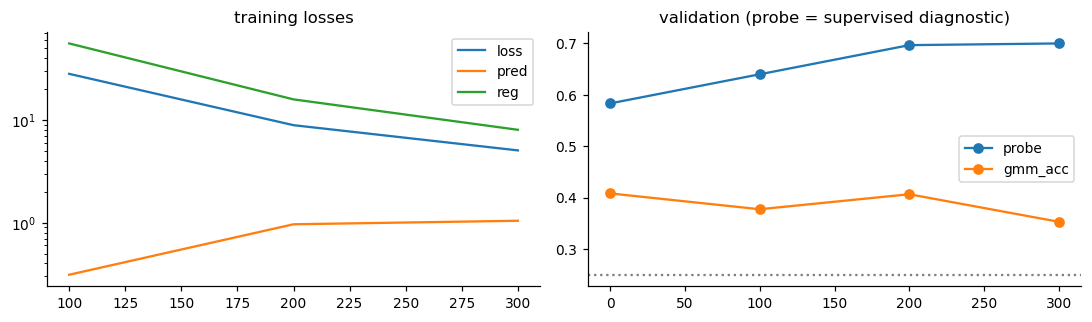

In [12]:
# training curves of a learnt feature learner, read from its run directory
f = make_learner("jepa_shared", window=32, gap=32, **small)
log = [json.loads(l) for l in open(os.path.join(bench.run_dir(f), "log.jsonl"))]
tr = pd.DataFrame([r for r in log if r["kind"] == "train"]); ev = pd.DataFrame([r for r in log if r["kind"] == "eval"])
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for c in [c for c in tr.columns if c not in ("step", "kind", "t")]: axs[0].plot(tr.step, tr[c], label=c)
axs[0].set_yscale("log"); axs[0].legend(); axs[0].set_title("training losses")
for c in ("probe", "gmm_acc"): axs[1].plot(ev.step, ev[c], marker="o", label=c)
axs[1].axhline(0.25, color="grey", ls=":"); axs[1].legend(); axs[1].set_title("validation (probe = supervised diagnostic)")
plt.tight_layout(); plt.show()

### Adding a feature learner or a detector

- **Learnt feature learner:** subclass `TorchFeatureLearner`, declare extra parameters in `defaults`, and implement `build(D, W)`. It returns a torch module with `loss(xc, xt) -> (loss, dict)` and `encode(x) -> (B, d)`. Training, checkpoints, feature caching and evaluation come for free.
- **Fixed feature learner:** subclass `FeatureLearner` and implement `embed(windows)`.
- **Detector:** subclass `Detector`, declare `defaults`, and implement `detect(Z, K, seed)`. It returns `dict(labels=(R, T) or None, cp_score=(R, T) or None)`.

Register each with `@register_learner(name)` / `@register_detector(name)`. Every learner can then be paired with every detector. To use them from the command line or on SLURM, put them in a module and pass `plugins=[that_module]`.

In [13]:
import torch.nn as nn
from cpbench import register_learner, register_detector, TorchFeatureLearner, Detector

class LinearAENet(nn.Module):
    def __init__(self, D, W, d):
        super().__init__(); self.enc = nn.Linear(D * W, d); self.dec = nn.Linear(d, D * W)
    def loss(self, xc, xt):
        l = (self.dec(self.enc(xc.flatten(1))) - xc.flatten(1)).square().mean(); return l, dict(rec=l.item())
    def encode(self, x):
        return self.enc(x.flatten(1))

@register_learner("linear_ae")
class LinearAE(TorchFeatureLearner):
    """A deliberately simple learnt feature learner: linear autoencoder on the flattened window."""
    defaults = dict(d=16)
    def build(self, D, W):
        return LinearAENet(D, W, self.d)

@register_detector("quantile_bins")
class QuantileBins(Detector):
    """A deliberately simple detector: regimes = quantile bins of one feature; change score = jump size."""
    defaults = dict(channel=0)
    def detect(self, Z, K, seed=0):
        z = Z[..., self.channel]; lab = np.digitize(z, np.quantile(z, np.linspace(0, 1, K + 1)[1:-1]))
        score = np.zeros_like(z); score[:, 1:] = np.abs(np.diff(z, axis=1))
        return dict(labels=lab, cp_score=score)

bench3 = Benchmark(DATASET, detectors=["quantile_bins", "hmm"], probes=False, quick=True, out="cpbench_runs_local", log=lambda *a: None)
df = pd.concat([bench3.run(make_learner("linear_ae", window=32, **small)), bench3.run(make_learner("raw_stats", window=16))])
df[df.metric.isin(["acc", "cp_ap"])].pivot_table(index=["features", "detector"], columns="metric", values="value").round(3)

metric                     acc  cp_ap
features  detector                   
linear_ae hmm            0.277  0.119
          quantile_bins  0.271  0.101
raw_stats hmm            0.980  0.912
          quantile_bins  0.307  0.166

## 7. HPC sweeps and the leaderboard

1. Edit `cpbench/configs/sweep_first.yaml`: the dataset grid, the feature learners and their hyperparameters, the fixed baselines, the detectors, the partition and the conda setup.
2. Run `python -m cpbench.hpc.make_sweep cpbench/configs/sweep_first.yaml` and `sbatch sweeps/first_sweep/job.sbatch`. Each job runs `python -m cpbench.run <line>`: fit one learner, then every detector on its features.
3. Copy `cpbench_runs/` back, or point `RUNS` at it, and run `python -m cpbench.results.aggregate cpbench_runs cpbench_results/results.csv`.

**The leaderboard fixes one detector and one metric in advance**: no per-dataset selection with labels. Rows are feature learner × window × gap; collapsing those hyperparameters needs a label-free selection rule, applied as a separate, explicit step.

In [14]:
res_path = os.path.join(RESULTS, "results.csv")
if os.path.exists(res_path):
    from cpbench.results.aggregate import table
    res = pd.read_csv(res_path)
    for detector, metric in [("hmm", "acc"), ("arhmm", "acc"), ("temporal_excess", "acc"), ("hmm", "cp_ap"), ("bocpd", "cp_ap")]:
        m, s = table(res, metric, detector)
        if m.size:
            print(f"--- detector {detector}, metric {metric} (mean over seeds) ---"); display(m)
else:
    print("no aggregated results yet:", res_path)

no aggregated results yet: cpbench_results/results.csv
